In [1]:
!pip install pandas numpy matplotlib seaborn scipy scikit-learn

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv("water_potability.csv")
df

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0
...,...,...,...,...,...,...,...,...,...,...
3271,4.668102,193.681735,47580.991603,7.166639,359.948574,526.424171,13.894419,66.687695,4.435821,1
3272,7.808856,193.553212,17329.802160,8.061362,NaN,392.449580,19.903225,NaN,2.798243,1
3273,9.419510,175.762646,33155.578218,7.350233,NaN,432.044783,11.039070,69.845400,3.298875,1
3274,5.126763,230.603758,11983.869376,6.303357,NaN,402.883113,11.168946,77.488213,4.708658,1


#### Data Understanding

In [4]:
df.shape

(3276, 10)

In [5]:
df.columns

Index(['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity',
       'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


#### Check Statistic Summary

In [7]:
df.describe()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000,3276.000000
mean,7.080795,196.369496,22014.092526,7.122277,333.775777,426.205111,14.284970,66.396293,3.966786,0.390110
std,1.594320,32.879761,8768.570828,1.583085,41.416840,80.824064,3.308162,16.175008,0.780382,0.487849
min,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000,0.000000
25%,6.093092,176.850538,15666.690297,6.127421,307.699498,365.734414,12.065801,55.844536,3.439711,0.000000
50%,7.036752,196.967627,20927.833607,7.130299,333.073546,421.884968,14.218338,66.622485,3.955028,0.000000
75%,8.062066,216.667456,27332.762127,8.114887,359.950170,481.792304,16.557652,77.337473,4.500320,1.000000
max,14.000000,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000,1.000000


#### Check data types

In [8]:
df.dtypes

ph                 float64
Hardness           float64
Solids             float64
Chloramines        float64
Sulfate            float64
Conductivity       float64
Organic_carbon     float64
Trihalomethanes    float64
Turbidity          float64
Potability           int64
dtype: object

#### Data Cleaning

#### Check if the are null or NaN rows

In [9]:
df.isnull().sum()

ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

In [11]:
for col in ['ph', 'Sulfate', 'Trihalomethanes']:
    df[col] = df.groupby('Potability')[col].transform(lambda x: x.fillna(x.median()))

print(df.isnull().sum())

ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
Potability         0
dtype: int64


#### Check duplicates

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df_before_duplicates = df.copy()

print("Before removing duplicates:", df.shape)
print("Rows involved in duplicates:", df.duplicated(keep=False).sum())
print("Rows that will be removed:", df.duplicated().sum())

Before removing duplicates: (3276, 10)
Rows involved in duplicates: 0
Rows that will be removed: 0


In [14]:
df = df.drop_duplicates().reset_index(drop=True)

print("After removing duplicates:", df.shape)
print("Remaining exact duplicates:", df.duplicated().sum())

After removing duplicates: (3276, 10)
Remaining exact duplicates: 0


In [15]:
df.columns

Index(['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity',
       'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability'],
      dtype='str')

In [16]:
print(df["Potability"].value_counts())

Potability
0    1998
1    1278
Name: count, dtype: int64


In [17]:
numerical_columns = [
    "ph",
    "Hardness",
    "Solids",
    "Chloramines",
    "Sulfate",
    "Conductivity",
    "Organic_carbon",
    "Trihalomethanes",
    "Turbidity"
]

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    print("Column:", column)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower limit:", lower_limit)
    print("Upper limit:", upper_limit)
    print("Number of outliers:", len(outliers))
    print("-" * 50)

Column: ph
Q1: 6.277672635884397
Q3: 7.870049755247176
IQR: 1.5923771193627791
Lower limit: 3.889106956840228
Upper limit: 10.258615434291345
Number of outliers: 142
--------------------------------------------------
Column: Hardness
Q1: 176.85053787752437
Q3: 216.66745621487073
IQR: 39.81691833734635
Lower limit: 117.12516037150485
Upper limit: 276.3928337208903
Number of outliers: 83
--------------------------------------------------
Column: Solids
Q1: 15666.69029696465
Q3: 27332.762127438615
IQR: 11666.071830473964
Lower limit: -1832.4174487462951
Upper limit: 44831.86987314956
Number of outliers: 47
--------------------------------------------------
Column: Chloramines
Q1: 6.1274207554913
Q3: 8.114887032109028
IQR: 1.9874662766177282
Lower limit: 3.1462213405647073
Upper limit: 11.09608644703562
Number of outliers: 61
--------------------------------------------------
Column: Sulfate
Q1: 317.0946377261117
Q3: 350.38575630240354
IQR: 33.29111857629181
Lower limit: 267.15795986167404

#### EDA (Exploratory Data Analysis)

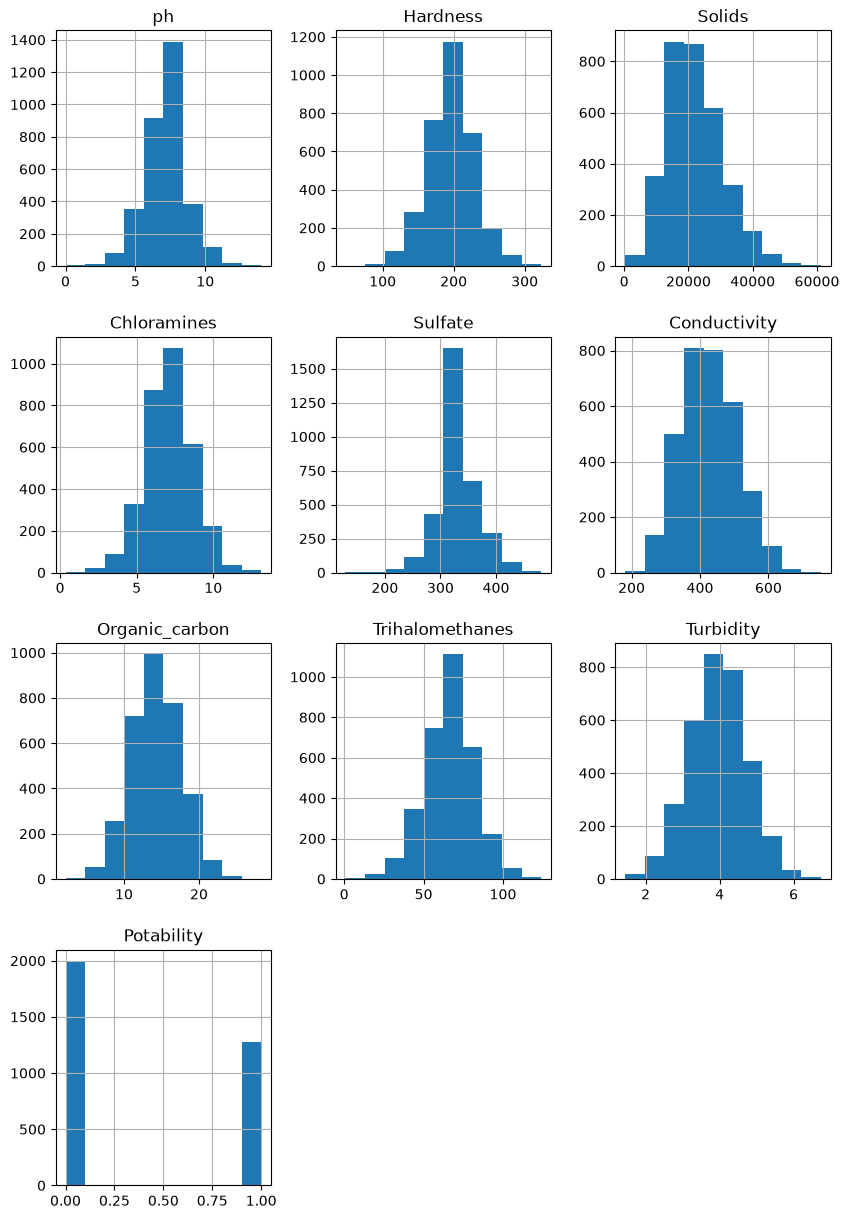

In [18]:
df.hist(figsize=(10,15))
plt.show()

#### bar graph: Potability

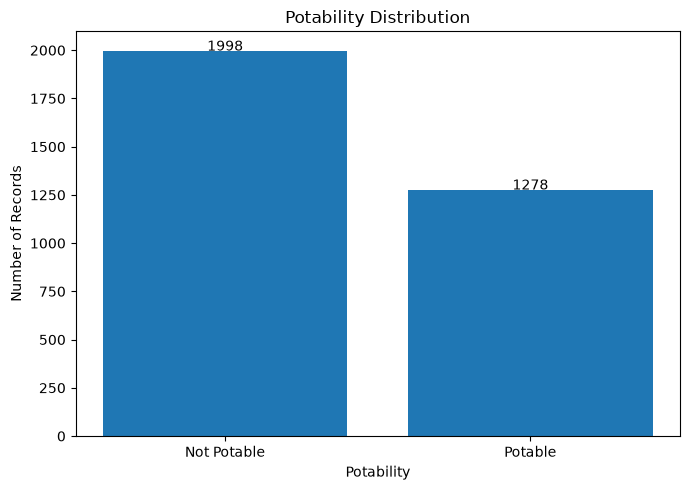

In [19]:
potability_counts = df["Potability"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["Not Potable", "Potable"],
    potability_counts.values
)

plt.title("Potability Distribution")
plt.xlabel("Potability")
plt.ylabel("Number of Records")

for bar, value in zip(bars, potability_counts.values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        str(value),
        ha="center"
    )

plt.tight_layout()
plt.show()

#### pH vs Sulfate

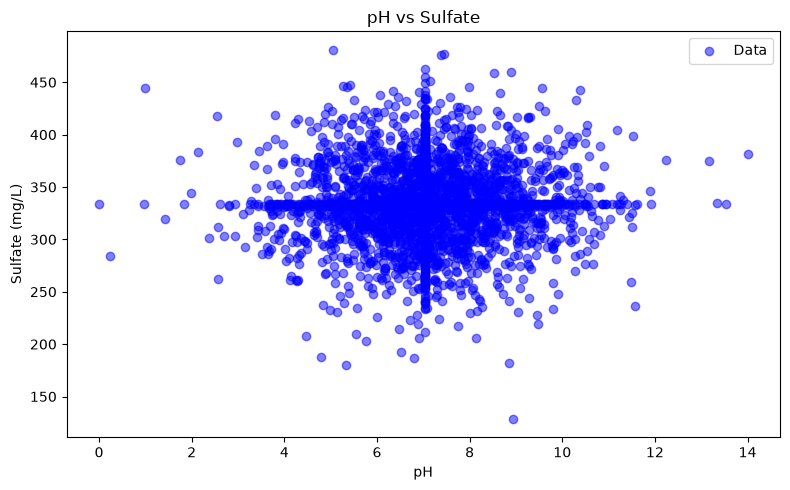

In [20]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["ph"],
    df["Sulfate"],
    color="blue",
    alpha=0.5,
    label="Data"
)

plt.title("pH vs Sulfate")
plt.xlabel("pH")
plt.ylabel("Sulfate (mg/L)")
plt.legend()
plt.tight_layout()
plt.show()

#### average pH for each potability status

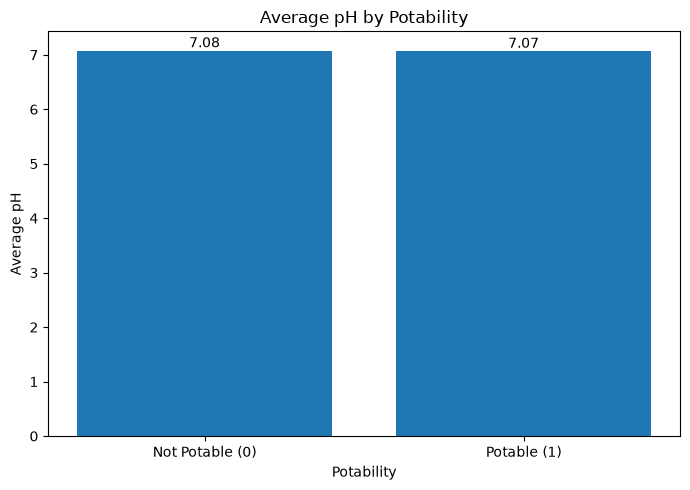

In [21]:
# Calculate average pH for each potability status
ph_by_potability = df.groupby("Potability")["ph"].mean()

plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["Not Potable (0)", "Potable (1)"],
    ph_by_potability.values
)

plt.title("Average pH by Potability")
plt.xlabel("Potability")
plt.ylabel("Average pH")

# Add values above bars
for bar, value in zip(bars, ph_by_potability.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

#### Correlation

In [22]:
numeric_columns = [
    "ph",
    "Hardness",
    "Solids",
    "Chloramines",
    "Sulfate",
    "Conductivity",
    "Organic_carbon",
    "Trihalomethanes",
    "Turbidity",
    "Potability"
]

correlation = df[numeric_columns].corr()
print(correlation)

                       ph  Hardness    Solids  Chloramines   Sulfate  \
ph               1.000000  0.075754 -0.082006    -0.031738  0.014454   
Hardness         0.075754  1.000000 -0.046899    -0.030054 -0.092824   
Solids          -0.082006 -0.046899  1.000000    -0.070148 -0.149684   
Chloramines     -0.031738 -0.030054 -0.070148     1.000000  0.023516   
Sulfate          0.014454 -0.092824 -0.149684     0.023516  1.000000   
Conductivity     0.017469 -0.023915  0.013831    -0.020486 -0.014341   
Organic_carbon   0.040240  0.003610  0.010242    -0.012653  0.027567   
Trihalomethanes  0.003146 -0.012721 -0.008793     0.016609 -0.025841   
Turbidity       -0.036106 -0.014449  0.019546     0.002363 -0.009550   
Potability      -0.002946 -0.013837  0.033743     0.023779 -0.025339   

                 Conductivity  Organic_carbon  Trihalomethanes  Turbidity  \
ph                   0.017469        0.040240         0.003146  -0.036106   
Hardness            -0.023915        0.003610        

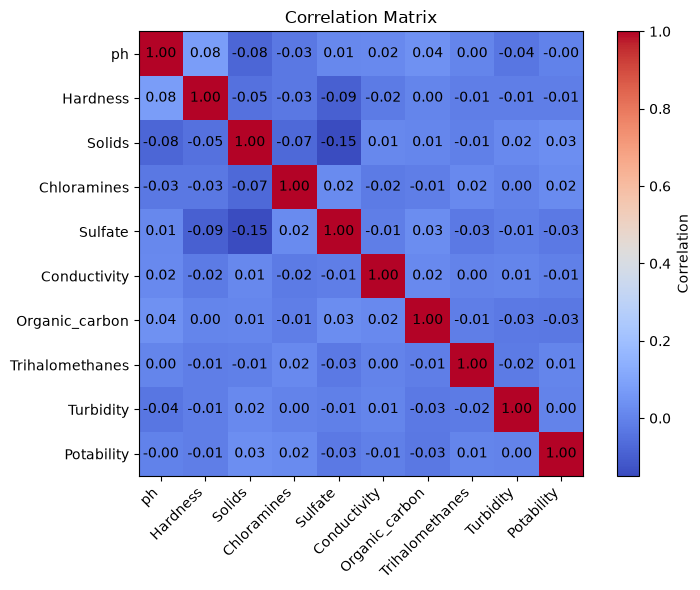

In [23]:
plt.figure(figsize=(8, 6))

plt.imshow(correlation, cmap="coolwarm", interpolation="nearest")

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Matrix")

# Display correlation values
for i in range(len(correlation)):
    for j in range(len(correlation)):
        plt.text(
            j,
            i,
            f"{correlation.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

#### Prepare the data

In [24]:
# Features and target

X = df[
    [
        "ph",
        "Hardness",
        "Solids",
        "Chloramines",
        "Sulfate",
        "Conductivity",
        "Organic_carbon",
        "Trihalomethanes",
        "Turbidity"
    ]
]

y = df["Potability"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (3276, 9)
y shape: (3276,)


####  Train/Test Split

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target:")
print(y_train.value_counts())

print("\nTesting target:")
print(y_test.value_counts())

Training data: (2620, 9)
Testing data: (656, 9)

Training target:
Potability
0    1598
1    1022
Name: count, dtype: int64

Testing target:
Potability
0    400
1    256
Name: count, dtype: int64


#### Balance ONLY the training data

In [26]:
print(y_train.value_counts())

Potability
0    1598
1    1022
Name: count, dtype: int64


#### Balance the training data manually

In [27]:
# Combine X_train and y_train
train_data = X_train.copy()
train_data["Potability"] = y_train.values

# Separate the two classes
not_potable = train_data[train_data["Potability"] == 0]
potable = train_data[train_data["Potability"] == 1]

# Find the larger class
max_count = max(len(not_potable), len(potable))

# Oversample the smaller class
not_potable_oversampled = not_potable.sample(
    n=max_count,
    replace=True,
    random_state=42
)

potable_oversampled = potable.sample(
    n=max_count,
    replace=True,
    random_state=42
)

# Combine the classes
train_balanced = pd.concat(
    [not_potable_oversampled, potable_oversampled]
)

# Shuffle the data
train_balanced = train_balanced.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

# Separate X and y
X_train_balanced = train_balanced.drop(
    "Potability",
    axis=1
)
y_train_balanced = train_balanced["Potability"]

# Check the results
print("Before balancing:")
print(y_train.value_counts())

print("\nAfter oversampling:")
print(y_train_balanced.value_counts())

Before balancing:
Potability
0    1598
1    1022
Name: count, dtype: int64

After oversampling:
Potability
1    1598
0    1598
Name: count, dtype: int64


In [28]:
print("Test set:")
print(y_test.value_counts())

Test set:
Potability
0    400
1    256
Name: count, dtype: int64


#### Train the ML models

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC

#### Create the models

In [31]:

models_tuned = {

    "Logistic Regression": LogisticRegression(
        max_iter=500
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=7,
        min_samples_split=20,
        min_samples_leaf=10,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        min_samples_split=20,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        max_depth=2,
        min_samples_split=20,
        min_samples_leaf=10,
        learning_rate=0.05,
        random_state=42
    )
}

#### Train and test all models

In [32]:
from sklearn.metrics import accuracy_score

results = []

for name, model in models_tuned.items():

    print(f"\nTraining {name}...")

    # Train on balanced training data
    model.fit(
        X_train_balanced,
        y_train_balanced
    )

    print(f"Testing {name}...")

    # Training accuracy
    train_pred = model.predict(X_train_balanced)
    train_accuracy = accuracy_score(
        y_train_balanced,
        train_pred
    )

    # Testing accuracy
    test_pred = model.predict(X_test)
    test_accuracy = accuracy_score(
        y_test,
        test_pred
    )

    difference = train_accuracy - test_accuracy

    results.append({
        "Model": name,
        "Training Accuracy": train_accuracy * 100,
        "Testing Accuracy": test_accuracy * 100,
        "Difference": difference * 100
    })

    print(f"Training Accuracy: {train_accuracy * 100:.2f}%")
    print(f"Testing Accuracy: {test_accuracy * 100:.2f}%")
    print(f"Difference: {difference * 100:.2f}%")


Training Logistic Regression...


C:\Users\Nontuthuko\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Testing Logistic Regression...
Training Accuracy: 52.32%
Testing Accuracy: 49.09%
Difference: 3.23%

Training Decision Tree...
Testing Decision Tree...
Training Accuracy: 82.57%
Testing Accuracy: 75.76%
Difference: 6.81%

Training Random Forest...
Testing Random Forest...
Training Accuracy: 83.01%
Testing Accuracy: 76.83%
Difference: 6.18%

Training Gradient Boosting...
Testing Gradient Boosting...
Training Accuracy: 78.38%
Testing Accuracy: 73.48%
Difference: 4.90%


In [33]:
results_df = pd.DataFrame(results)

print("\n===== TUNED MODEL RESULTS =====")
print(results_df.round(2))


===== TUNED MODEL RESULTS =====
                 Model  Training Accuracy  Testing Accuracy  Difference
0  Logistic Regression              52.32             49.09        3.23
1        Decision Tree              82.57             75.76        6.81
2        Random Forest              83.01             76.83        6.18
3    Gradient Boosting              78.38             73.48        4.90


#### confusion_matrix

Confusion Matrix:
[[321  79]
 [ 73 183]]


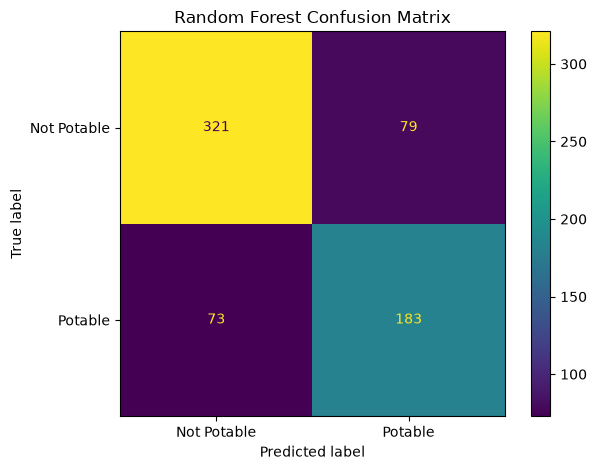

In [34]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Get the Random Forest
random_forest = models_tuned["Random Forest"]

# Predict on the original test data
y_pred_rf = random_forest.predict(X_test)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred_rf)

print("Confusion Matrix:")
print(cm)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Potable", "Potable"]
)

disp.plot()
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

In [36]:
from sklearn.metrics import classification_report

print("Random Forest Classification Report")
print("=" * 50)

print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["Not Potable", "Potable"]
    )
)

Random Forest Classification Report
              precision    recall  f1-score   support

 Not Potable       0.81      0.80      0.81       400
     Potable       0.70      0.71      0.71       256

    accuracy                           0.77       656
   macro avg       0.76      0.76      0.76       656
weighted avg       0.77      0.77      0.77       656



#### Calculate feature importance

In [38]:
# Get feature importance
importance = random_forest.feature_importances_

# Create DataFrame
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

           Feature  Importance
4          Sulfate    0.461318
0               ph    0.270185
3      Chloramines    0.066177
1         Hardness    0.061420
2           Solids    0.049076
6   Organic_carbon    0.025324
7  Trihalomethanes    0.022237
5     Conductivity    0.022139
8        Turbidity    0.022124


#### Predict  future observations

In [39]:
# ==========================================
# NEW WATER SAMPLE
# ==========================================

new_water = pd.DataFrame([[
    7.0,       # ph
    200.0,     # Hardness
    20000.0,   # Solids
    7.0,       # Chloramines
    330.0,     # Sulfate
    420.0,     # Conductivity
    14.0,      # Organic_carbon
    66.0,      # Trihalomethanes
    4.0        # Turbidity
]], columns=X_train.columns)

# ==========================================
# PREDICTION
# ==========================================

prediction = random_forest.predict(new_water)

if prediction[0] == 1:
    print("Prediction: POTABLE")
else:
    print("Prediction: NOT POTABLE")

# ==========================================
# GET PROBABILITIES
# ==========================================

probability = random_forest.predict_proba(new_water)[0]

print("Probability of NOT POTABLE:", round(probability[0] * 100, 2), "%")
print("Probability of POTABLE:", round(probability[1] * 100, 2), "%")

Prediction: NOT POTABLE
Probability of NOT POTABLE: 59.68 %
Probability of POTABLE: 40.32 %


#### ROC_AUC (ROC = Receiver Operating Characteristic, AUC = Area Under the Curve)

In [40]:
from sklearn.metrics import roc_auc_score

# Get the trained Random Forest model
random_forest = models_tuned["Random Forest"]

# Get probability of class 1 (POTABLE)
y_prob = random_forest.predict_proba(X_test)[:, 1]

# Calculate ROC-AUC
roc_auc = roc_auc_score(y_test, y_prob)

print("Random Forest ROC-AUC:", roc_auc)

Random Forest ROC-AUC: 0.8567480468750001


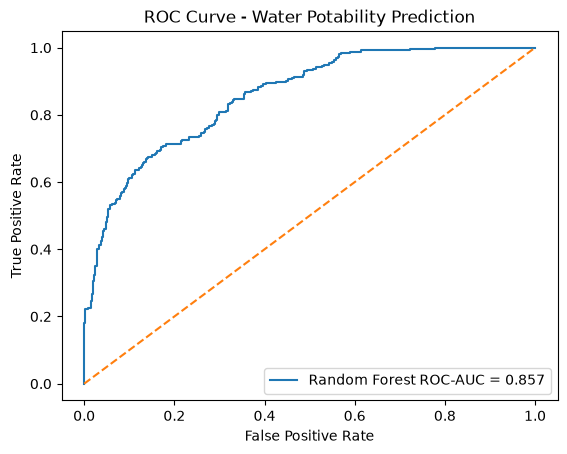

In [41]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Get the trained Random Forest model
random_forest = models_tuned["Random Forest"]

# Get probability of class 1 (POTABLE)
y_prob = random_forest.predict_proba(X_test)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate ROC-AUC
auc = roc_auc_score(y_test, y_prob)

# Plot ROC curve
plt.plot(fpr, tpr, label=f"Random Forest ROC-AUC = {auc:.3f}")

# Random guessing line
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Water Potability Prediction")
plt.legend()
plt.show()

#### Save the Decision Tree model and  feature names

In [42]:
import joblib

# Get the trained Random Forest
random_forest = models_tuned["Random Forest"]

# Store model and feature names
model_data = {
    "model": random_forest,
    "features": X_train.columns.tolist()
}

# Save the Random Forest
joblib.dump(model_data, "random_forest_potability_model.pkl")

print("Random Forest model and feature names saved successfully.")

Random Forest model and feature names saved successfully.


#### Load the model

In [44]:
import joblib

# ==========================================
# LOAD THE SAVED RANDOM FOREST MODEL
# ==========================================

model_data = joblib.load("random_forest_potability_model.pkl")

# Get the model
loaded_model = model_data["model"]

# Get feature names
feature_names = model_data["features"]

print("Random Forest model loaded successfully.")

print("Features:")
print(feature_names)

Random Forest model loaded successfully.
Features:
['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']


In [46]:
result = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred_rf
})

result['Actual'] = result['Actual'].map({
    0: 'Not Potable',
    1: 'Potable'
})

result['Predicted'] = result['Predicted'].map({
    0: 'Not Potable',
    1: 'Potable'
})

print(result.head(30))

           Actual    Predicted
664       Potable      Potable
2530  Not Potable  Not Potable
2870  Not Potable  Not Potable
1045  Not Potable  Not Potable
95    Not Potable  Not Potable
1793  Not Potable  Not Potable
202   Not Potable      Potable
1766  Not Potable  Not Potable
1960      Potable  Not Potable
1558      Potable      Potable
207   Not Potable  Not Potable
2645  Not Potable  Not Potable
1127      Potable      Potable
2915  Not Potable  Not Potable
1580      Potable      Potable
1661  Not Potable  Not Potable
2097  Not Potable      Potable
2710      Potable      Potable
1893      Potable      Potable
1802  Not Potable  Not Potable
2064  Not Potable  Not Potable
3199      Potable      Potable
1776  Not Potable  Not Potable
1763  Not Potable  Not Potable
1493      Potable  Not Potable
2082  Not Potable      Potable
2911  Not Potable      Potable
648   Not Potable  Not Potable
801       Potable  Not Potable
1130      Potable  Not Potable


#### Check the loaded ds if it works

In [48]:
# ==========================================
# PREDICTION
# ==========================================

prediction = loaded_model.predict(new_water)

probability = loaded_model.predict_proba(new_water)[0]


# ==========================================
# RESULT
# ==========================================

if prediction[0] == 1:
    print("Prediction: Potable")
else:
    print("Prediction: NO Potable")


# ==========================================
# PROBABILITIES
# ==========================================

print("Probability of NO Potable:", round(probability[0] * 100, 2), "%")
print("Probability of Potable:", round(probability[1] * 100, 2), "%")

Prediction: NO Potable
Probability of NO Potable: 59.68 %
Probability of Potable: 40.32 %


In [56]:
#### FORECASTING ALGORITHM

In [50]:
import pandas as pd

df_brisbane = pd.read_csv("brisbane_water_quality.csv")

df_brisbane["Timestamp"] = pd.to_datetime(df_brisbane["Timestamp"])

print("Shape:", df_brisbane.shape)
print("\nDate range:", df_brisbane["Timestamp"].min(), "to", df_brisbane["Timestamp"].max())
print("\nColumns:")
print(df_brisbane.columns.tolist())
print("\nNull counts:")
print(df_brisbane.isnull().sum())

Shape: (30894, 20)

Date range: 2023-08-04 23:00:00 to 2024-06-27 09:00:00

Columns:
['Timestamp', 'Record number', 'Average Water Speed', 'Average Water Direction', 'Chlorophyll', 'Chlorophyll [quality]', 'Temperature', 'Temperature [quality]', 'Dissolved Oxygen', 'Dissolved Oxygen [quality]', 'Dissolved Oxygen (%Saturation)', 'Dissolved Oxygen (%Saturation) [quality]', 'pH', 'pH [quality]', 'Salinity', 'Salinity [quality]', 'Specific Conductance', 'Specific Conductance [quality]', 'Turbidity', 'Turbidity [quality]']

Null counts:
Timestamp                                      0
Record number                                  0
Average Water Speed                           20
Average Water Direction                        1
Chlorophyll                                  585
Chlorophyll [quality]                        808
Temperature                                 5164
Temperature [quality]                       5344
Dissolved Oxygen                            4300
Dissolved Oxygen [qua

In [51]:
###Cell 2: Clean the data — drop quality columns, handle duplicates, keep only what we need

In [52]:
# Drop the [quality] flag columns and Record number (not needed for forecasting)
quality_cols = [col for col in df_brisbane.columns if "quality" in col.lower()]
df_brisbane = df_brisbane.drop(columns=quality_cols + ["Record number"])

# Handle duplicate timestamps by averaging them
df_brisbane = df_brisbane.groupby("Timestamp", as_index=False).mean()

# Sort by time
df_brisbane = df_brisbane.sort_values("Timestamp").reset_index(drop=True)

print("Shape after cleaning:", df_brisbane.shape)
print("\nColumns:")
print(df_brisbane.columns.tolist())
print("\nDuplicate timestamps remaining:", df_brisbane["Timestamp"].duplicated().sum())

Shape after cleaning: (30614, 11)

Columns:
['Timestamp', 'Average Water Speed', 'Average Water Direction', 'Chlorophyll', 'Temperature', 'Dissolved Oxygen', 'Dissolved Oxygen (%Saturation)', 'pH', 'Salinity', 'Specific Conductance', 'Turbidity']

Duplicate timestamps remaining: 0


In [53]:
###Cell 3: Resample to daily averages, focus on pH and Turbidity

In [57]:
# Set Timestamp as the index so we can resample by day
df_daily = df_brisbane.set_index("Timestamp")[["pH", "Turbidity"]]

# Resample to daily averages
df_daily = df_daily.resample("D").mean()

print("Shape:", df_daily.shape)
print("\nMissing days:")
print(df_daily.isnull().sum())

df_daily.head(10)

Shape: (329, 2)

Missing days:
pH           31
Turbidity    35
dtype: int64


,pH,Turbidity
Timestamp,,
2023-08-04,8.168500,2.006917
2023-08-05,8.163809,2.045064
2023-08-06,8.166021,1.932333
2023-08-07,8.176604,1.720875
2023-08-08,8.172417,1.858396
2023-08-09,8.169063,1.984750
2023-08-10,8.163562,2.549812
2023-08-11,8.162250,2.077646
2023-08-12,8.157312,1.756417


In [58]:
#### Fill missing days with interpolation

In [59]:
# Interpolate missing values (fills gaps using surrounding days' trend)
df_daily = df_daily.interpolate(method="linear")

print("Missing values after interpolation:")
print(df_daily.isnull().sum())

df_daily.head(10)

Missing values after interpolation:
pH           0
Turbidity    0
dtype: int64


,pH,Turbidity
Timestamp,,
2023-08-04,8.168500,2.006917
2023-08-05,8.163809,2.045064
2023-08-06,8.166021,1.932333
2023-08-07,8.176604,1.720875
2023-08-08,8.172417,1.858396
2023-08-09,8.169063,1.984750
2023-08-10,8.163562,2.549812
2023-08-11,8.162250,2.077646
2023-08-12,8.157312,1.756417


In [60]:
#### Install/import ARIMA

In [70]:
!pip install statsmodels

In [71]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, r2_score
import warnings
warnings.filterwarnings("ignore")

print("Ready for ARIMA modeling")

Ready for ARIMA modeling


In [ ]:
#### Train/test split

In [72]:
# Same 80/20 chronological split as before, but just on the raw series
split_index = int(len(df_daily) * 0.8)

train_ph = df_daily["pH"].iloc[:split_index]
test_ph = df_daily["pH"].iloc[split_index:]

train_turbidity = df_daily["Turbidity"].iloc[:split_index]
test_turbidity = df_daily["Turbidity"].iloc[split_index:]

print("Training days:", len(train_ph))
print("Testing days:", len(test_ph))

Training days: 263
Testing days: 66


In [ ]:
#### Fit ARIMA on pH and check the summary

In [73]:
# ARIMA(p, d, q) - starting with a simple order
model_ph = ARIMA(train_ph, order=(2, 1, 2))
model_ph_fit = model_ph.fit()

print(model_ph_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                     pH   No. Observations:                  263
Model:                 ARIMA(2, 1, 2)   Log Likelihood                 630.289
Date:                Thu, 03 Sep 2026   AIC                          -1250.578
Time:                        23:27:36   BIC                          -1232.737
Sample:                    08-04-2023   HQIC                         -1243.407
                         - 04-22-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.0850      0.128      8.473      0.000       0.834       1.336
ar.L2         -0.4437      0.122     -3.635      0.000      -0.683      -0.204
ma.L1         -0.8964      0.132     -6.770      0.0

In [ ]:
#### Fit ARIMA on Turbidity

In [74]:
model_turbidity = ARIMA(train_turbidity, order=(2, 1, 2))
model_turbidity_fit = model_turbidity.fit()

print(model_turbidity_fit.summary())

                               SARIMAX Results                                
Dep. Variable:              Turbidity   No. Observations:                  263
Model:                 ARIMA(2, 1, 2)   Log Likelihood                -379.006
Date:                Thu, 03 Sep 2026   AIC                            768.012
Time:                        23:28:31   BIC                            785.854
Sample:                    08-04-2023   HQIC                           775.183
                         - 04-22-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1610      0.043     -3.714      0.000      -0.246      -0.076
ar.L2          0.8252      0.051     16.299      0.000       0.726       0.924
ma.L1          0.0151      0.403      0.038      0.9

In [ ]:
#### Forecast on the test set and evaluate

In [75]:
# Forecast the same number of days as the test set
forecast_ph = model_ph_fit.forecast(steps=len(test_ph))
forecast_turbidity = model_turbidity_fit.forecast(steps=len(test_turbidity))

# Evaluate pH
mae_ph_arima = mean_absolute_error(test_ph, forecast_ph)
r2_ph_arima = r2_score(test_ph, forecast_ph)

# Evaluate Turbidity
mae_turbidity_arima = mean_absolute_error(test_turbidity, forecast_turbidity)
r2_turbidity_arima = r2_score(test_turbidity, forecast_turbidity)

print("ARIMA - pH Model:")
print(f"  MAE: {mae_ph_arima:.4f}")
print(f"  R²: {r2_ph_arima:.4f}")

print("\nARIMA - Turbidity Model:")
print(f"  MAE: {mae_turbidity_arima:.4f}")
print(f"  R²: {r2_turbidity_arima:.4f}")

ARIMA - pH Model:
  MAE: 0.0328
  R²: -1.5193

ARIMA - Turbidity Model:
  MAE: 3.7871
  R²: -0.5416


In [ ]:
#### One-step-ahead ARIMA evaluation (fair comparison to RF)

In [77]:
# Rolling one-step-ahead forecast: refit-free approach using ARIMA's append method
history_ph_arima = train_ph.copy()
history_turbidity_arima = train_turbidity.copy()

predictions_ph_step = []
predictions_turbidity_step = []

for i in range(len(test_ph)):
    # Fit on all data seen so far
    model_ph_temp = ARIMA(history_ph_arima, order=(2, 1, 2)).fit()
    model_turbidity_temp = ARIMA(history_turbidity_arima, order=(2, 1, 2)).fit()

    # Forecast just the next day
    next_ph = model_ph_temp.forecast(steps=1).iloc[0]
    next_turbidity = model_turbidity_temp.forecast(steps=1).iloc[0]

    predictions_ph_step.append(next_ph)
    predictions_turbidity_step.append(next_turbidity)

    # Add the REAL observed value to history (not the prediction) before next loop
    history_ph_arima = pd.concat([history_ph_arima, test_ph.iloc[[i]]])
    history_turbidity_arima = pd.concat([history_turbidity_arima, test_turbidity.iloc[[i]]])

# Evaluate
mae_ph_step = mean_absolute_error(test_ph, predictions_ph_step)
r2_ph_step = r2_score(test_ph, predictions_ph_step)

mae_turbidity_step = mean_absolute_error(test_turbidity, predictions_turbidity_step)
r2_turbidity_step = r2_score(test_turbidity, predictions_turbidity_step)

print("ARIMA One-Step-Ahead - pH Model:")
print(f"  MAE: {mae_ph_step:.4f}")
print(f"  R²: {r2_ph_step:.4f}")

print("\nARIMA One-Step-Ahead - Turbidity Model:")
print(f"  MAE: {mae_turbidity_step:.4f}")
print(f"  R²: {r2_turbidity_step:.4f}")

ARIMA One-Step-Ahead - pH Model:
  MAE: 0.0079
  R²: 0.7897

ARIMA One-Step-Ahead - Turbidity Model:
  MAE: 1.1393
  R²: 0.7550


In [ ]:
#### Forecast tomorrow's pH and Turbidity using ARIMA (trained on all available data

In [78]:
# Refit on the FULL dataset (train + test) to get the best possible forecast for tomorrow
final_model_ph = ARIMA(df_daily["pH"], order=(2, 1, 2)).fit()
final_model_turbidity = ARIMA(df_daily["Turbidity"], order=(2, 1, 2)).fit()

# Forecast 1 day ahead
forecast_ph_tomorrow = final_model_ph.forecast(steps=1).iloc[0]
forecast_turbidity_tomorrow = final_model_turbidity.forecast(steps=1).iloc[0]

print("ARIMA Forecast for Tomorrow:")
print(f"  pH: {forecast_ph_tomorrow:.4f}")
print(f"  Turbidity: {forecast_turbidity_tomorrow:.4f}")

ARIMA Forecast for Tomorrow:
  pH: 8.1591
  Turbidity: 4.0615


In [ ]:
#### Build the feature vector and predict potability

In [79]:
other_features_avg = df[[
    "Hardness", "Solids", "Chloramines",
    "Sulfate", "Conductivity", "Organic_carbon", "Trihalomethanes"
]].mean()

# Build the full feature row - must match the exact column order from X_train
new_water_forecast = pd.DataFrame([[
    forecast_ph_tomorrow,                    # ph (forecasted)
    other_features_avg["Hardness"],          # Hardness (average)
    other_features_avg["Solids"],            # Solids (average)
    other_features_avg["Chloramines"],       # Chloramines (average)
    other_features_avg["Sulfate"],           # Sulfate (average)
    other_features_avg["Conductivity"],      # Conductivity (average)
    other_features_avg["Organic_carbon"],    # Organic_carbon (average)
    other_features_avg["Trihalomethanes"],   # Trihalomethanes (average)
    forecast_turbidity_tomorrow              # Turbidity (forecasted)
]], columns=X_train.columns)

print(new_water_forecast)

         ph    Hardness        Solids  Chloramines     Sulfate  Conductivity  \
0  8.159095  196.369496  22014.092526     7.122277  333.544928    426.205111   

   Organic_carbon  Trihalomethanes  Turbidity  
0        14.28497        66.405792   4.061494  


In [ ]:
#### Predict potability from the forecasted water conditions

In [80]:
prediction = random_forest.predict(new_water_forecast)
probability = random_forest.predict_proba(new_water_forecast)[0]

print("Potability Forecast for Tomorrow")
print("=" * 40)

if prediction[0] == 1:
    print("Prediction: POTABLE")
else:
    print("Prediction: NOT POTABLE")

print(f"\nProbability of NOT POTABLE: {probability[0] * 100:.2f}%")
print(f"Probability of POTABLE: {probability[1] * 100:.2f}%")

Potability Forecast for Tomorrow
Prediction: NOT POTABLE

Probability of NOT POTABLE: 70.68%
Probability of POTABLE: 29.32%
